In [1]:
# COVID 19 DATA
# descriptive stat
# contry wise confirmed death

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("country_wise_latest.csv")
df.head()

,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa


In [5]:
df.describe()

,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase
count,1.870000e+02,187.000000,1.870000e+02,1.870000e+02,187.000000,187.000000,187.000000,187.000000,187.000000,187.00,1.870000e+02,187.000000,187.000000
mean,8.813094e+04,3497.518717,5.063148e+04,3.400194e+04,1222.957219,28.957219,933.812834,3.019519,64.820535,inf,7.868248e+04,9448.459893,13.606203
std,3.833187e+05,14100.002482,1.901882e+05,2.133262e+05,5710.374790,120.037173,4197.719635,3.454302,26.287694,NaN,3.382737e+05,47491.127684,24.509838
min,1.000000e+01,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,1.000000e+01,-47.000000,-3.840000
25%,1.114000e+03,18.500000,6.265000e+02,1.415000e+02,4.000000,0.000000,0.000000,0.945000,48.770000,1.45,1.051500e+03,49.000000,2.775000
50%,5.059000e+03,108.000000,2.815000e+03,1.600000e+03,49.000000,1.000000,22.000000,2.150000,71.320000,3.62,5.020000e+03,432.000000,6.890000
75%,4.046050e+04,734.000000,2.260600e+04,9.149000e+03,419.500000,6.000000,221.000000,3.875000,86.885000,6.44,3.708050e+04,3172.000000,16.855000
max,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06,56336.000000,1076.000000,33728.000000,28.560000,100.000000,inf,3.834677e+06,455582.000000,226.320000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country/Region          187 non-null    object 
 1   Confirmed               187 non-null    int64  
 2   Deaths                  187 non-null    int64  
 3   Recovered               187 non-null    int64  
 4   Active                  187 non-null    int64  
 5   New cases               187 non-null    int64  
 6   New deaths              187 non-null    int64  
 7   New recovered           187 non-null    int64  
 8   Deaths / 100 Cases      187 non-null    float64
 9   Recovered / 100 Cases   187 non-null    float64
 10  Deaths / 100 Recovered  187 non-null    float64
 11  Confirmed last week     187 non-null    int64  
 12  1 week change           187 non-null    int64  
 13  1 week % increase       187 non-null    float64
 14  WHO Region              187 non-null    ob

In [7]:
df.isnull().sum()

Country/Region            0
Confirmed                 0
Deaths                    0
Recovered                 0
Active                    0
New cases                 0
New deaths                0
New recovered             0
Deaths / 100 Cases        0
Recovered / 100 Cases     0
Deaths / 100 Recovered    0
Confirmed last week       0
1 week change             0
1 week % increase         0
WHO Region                0
dtype: int64

In [8]:
len(df)

187

In [10]:
df.columns

Index(['Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active',
       'New cases', 'New deaths', 'New recovered', 'Deaths / 100 Cases',
       'Recovered / 100 Cases', 'Deaths / 100 Recovered',
       'Confirmed last week', '1 week change', '1 week % increase',
       'WHO Region'],
      dtype='object')

In [12]:
df.rename(columns={"Country/Region":"Country"},inplace=True)
df.head()

,Country,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa


In [25]:
df1 = df.groupby("WHO Region")[["Deaths","Recovered"]].sum()

In [26]:
df1

,Deaths,Recovered
WHO Region,,
Africa,12223,440645
Americas,342732,4468616
Eastern Mediterranean,38339,1201400
Europe,211144,1993723
South-East Asia,41349,1156933
Western Pacific,8249,206770


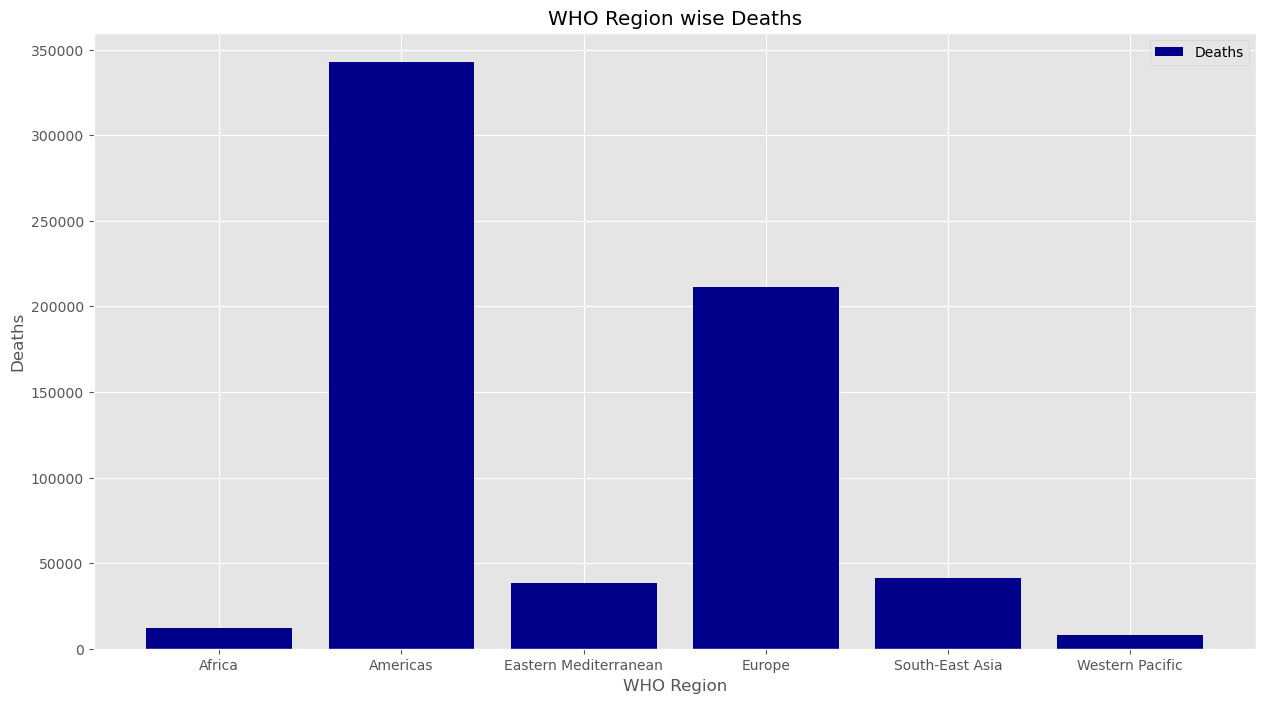

In [79]:
plt.style.use('ggplot')
plt.figure(figsize=(15,8))
plt.bar(df1.index,df1["Deaths"],color="darkblue",label="Deaths")
plt.xlabel("WHO Region")
plt.ylabel("Deaths")
plt.title("WHO Region wise Deaths")
plt.legend()
plt.show()

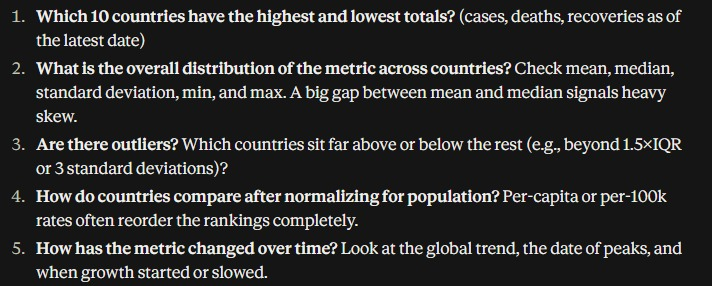

## 1. Which 10 countries have the highest and lowest totals? (cases, deaths, recoveries as of the latest date)

In [41]:
df.head()

,Country,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa


In [47]:
top_10 = df["Confirmed"].nlargest(10)
top_10

173    4290259
23     2442375
79     1480073
138     816680
154     452529
111     395489
132     389717
35      347923
177     301708
81      293606
Name: Confirmed, dtype: int64

In [45]:
lowest_10 = df["Confirmed"].nsmallest(10)
lowest_10

183    10
75     12
68     14
140    17
49     18
94     20
69     23
141    24
168    24
59     27
Name: Confirmed, dtype: int64

In [50]:
df2 = df.iloc[top_10.index]
df2

,Country,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
173,US,4290259,148011,1325804,2816444,56336,1076,27941,3.45,30.90,11.16,3834677,455582,11.88,Americas
23,Brazil,2442375,87618,1846641,508116,23284,614,33728,3.59,75.61,4.74,2118646,323729,15.28,Americas
79,India,1480073,33408,951166,495499,44457,637,33598,2.26,64.26,3.51,1155338,324735,28.11,South-East Asia
138,Russia,816680,13334,602249,201097,5607,85,3077,1.63,73.74,2.21,776212,40468,5.21,Europe
154,South Africa,452529,7067,274925,170537,7096,298,9848,1.56,60.75,2.57,373628,78901,21.12,Africa
111,Mexico,395489,44022,303810,47657,4973,342,8588,11.13,76.82,14.49,349396,46093,13.19,Americas
132,Peru,389717,18418,272547,98752,13756,575,4697,4.73,69.93,6.76,357681,32036,8.96,Americas
35,Chile,347923,9187,319954,18782,2133,75,1859,2.64,91.96,2.87,333029,14894,4.47,Americas
177,United Kingdom,301708,45844,1437,254427,688,7,3,15.19,0.48,3190.26,296944,4764,1.60,Europe
81,Iran,293606,15912,255144,22550,2434,212,1931,5.42,86.90,6.24,276202,17404,6.30,Eastern Mediterranean


In [58]:
df3=df.iloc[lowest_10.index]
df3

,Country,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
183,Western Sahara,10,1,8,1,0,0,0,10.0,80.00,12.5,10,0,0.00,Africa
75,Holy See,12,0,12,0,0,0,0,0.0,100.00,0.0,12,0,0.00,Europe
68,Greenland,14,0,13,1,1,0,0,0.0,92.86,0.0,13,1,7.69,Europe
140,Saint Kitts and Nevis,17,0,15,2,0,0,0,0.0,88.24,0.0,17,0,0.00,Americas
49,Dominica,18,0,18,0,0,0,0,0.0,100.00,0.0,18,0,0.00,Americas
94,Laos,20,0,19,1,0,0,0,0.0,95.00,0.0,19,1,5.26,Western Pacific
69,Grenada,23,0,23,0,0,0,0,0.0,100.00,0.0,23,0,0.00,Americas
141,Saint Lucia,24,0,22,2,0,0,0,0.0,91.67,0.0,23,1,4.35,Americas
168,Timor-Leste,24,0,0,24,0,0,0,0.0,0.00,0.0,24,0,0.00,South-East Asia
59,Fiji,27,0,18,9,0,0,0,0.0,66.67,0.0,27,0,0.00,Western Pacific


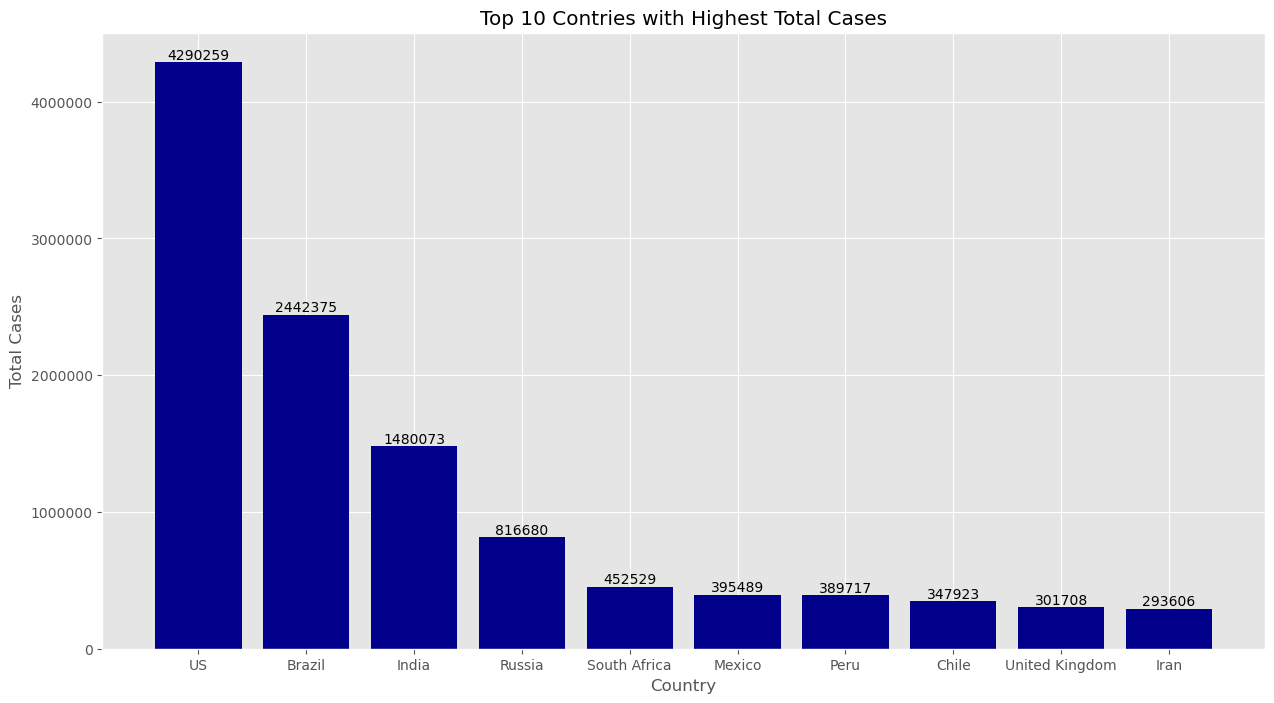

In [78]:
plt.style.use('ggplot')
plt.figure(figsize=(15,8))
bar = plt.bar(df2["Country"],df2["Confirmed"],color="darkblue")
plt.bar_label(bar,fmt="%.0f")
plt.xlabel("Country")
plt.ylabel("Total Cases")
plt.ticklabel_format(style="plain", axis="y")
plt.title("Top 10 Contries with Highest Total Cases")
plt.show()

#### Top 10 Contries with Lowest Total Cases

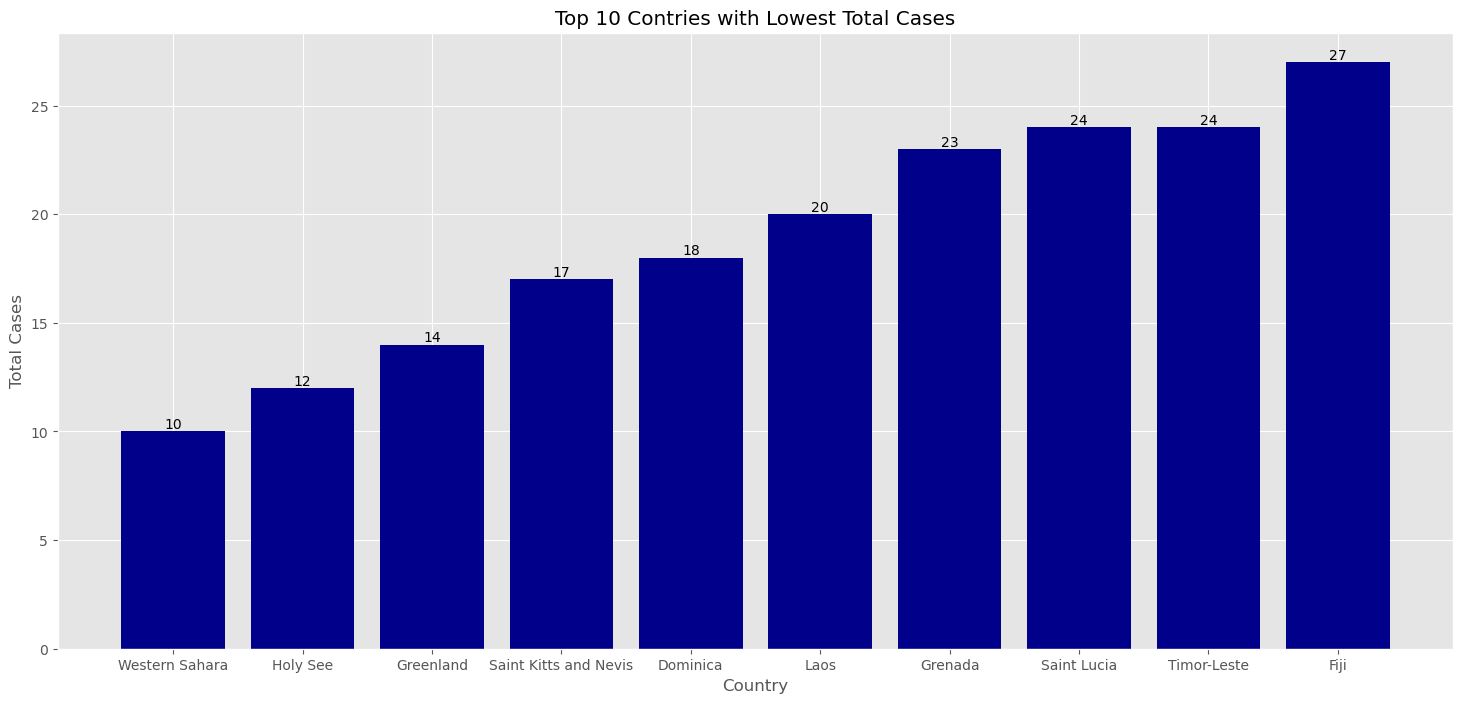

In [74]:
plt.style.use('ggplot')
plt.figure(figsize=(18,8))
bar= plt.bar(df3["Country"],df3["Confirmed"],color="darkblue")
plt.bar_label(bar,fmt="%.0f")
plt.xlabel("Country")
plt.ylabel("Total Cases")
plt.ticklabel_format(style="plain", axis="y")
plt.title("Top 10 Contries with Lowest Total Cases")
plt.show()

In [76]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

### 2. What is the overall distribution of the metric across countries? Check mean, median, standard deviation, min, and max. A big gap between mean and median signals heavy skew.

In [81]:
df.describe()

,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase
count,1.870000e+02,187.000000,1.870000e+02,1.870000e+02,187.000000,187.000000,187.000000,187.000000,187.000000,187.00,1.870000e+02,187.000000,187.000000
mean,8.813094e+04,3497.518717,5.063148e+04,3.400194e+04,1222.957219,28.957219,933.812834,3.019519,64.820535,inf,7.868248e+04,9448.459893,13.606203
std,3.833187e+05,14100.002482,1.901882e+05,2.133262e+05,5710.374790,120.037173,4197.719635,3.454302,26.287694,NaN,3.382737e+05,47491.127684,24.509838
min,1.000000e+01,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,1.000000e+01,-47.000000,-3.840000
25%,1.114000e+03,18.500000,6.265000e+02,1.415000e+02,4.000000,0.000000,0.000000,0.945000,48.770000,1.45,1.051500e+03,49.000000,2.775000
50%,5.059000e+03,108.000000,2.815000e+03,1.600000e+03,49.000000,1.000000,22.000000,2.150000,71.320000,3.62,5.020000e+03,432.000000,6.890000
75%,4.046050e+04,734.000000,2.260600e+04,9.149000e+03,419.500000,6.000000,221.000000,3.875000,86.885000,6.44,3.708050e+04,3172.000000,16.855000
max,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06,56336.000000,1076.000000,33728.000000,28.560000,100.000000,inf,3.834677e+06,455582.000000,226.320000


In [84]:
df["Confirmed"].describe()

count    1.870000e+02
mean     8.813094e+04
std      3.833187e+05
min      1.000000e+01
25%      1.114000e+03
50%      5.059000e+03
75%      4.046050e+04
max      4.290259e+06
Name: Confirmed, dtype: float64

### 3. Are there outliers? Which countries sit far above or below the rest (e.g., beyond 1.5×IQR or 3 standard deviations)?

In [85]:
df.head()

,Country,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa


In [95]:
q1 = df["Confirmed"].quantile(0.25)
q2 = df["Confirmed"].median()
q3 = df["Confirmed"].quantile(0.75)
iqr = q3 - q2
lower_bound = q1 - iqr*1.5
upper_bound = q3 + iqr*1.5

print("Q1 : ",q1)
print("Q2 : ",q2)
print("Q3 : ",q3)
print("lower_bound : ",lower_bound)
print("upper_bound : ",upper_bound)

Q1 :  1114.0
Q2 :  5059.0
Q3 :  40460.5
lower_bound :  -51988.25
upper_bound :  93562.75


In [99]:
iqr_outliers = df[(df["Confirmed"] < lower_bound) | (df["Confirmed"] > upper_bound)][["Country", "Confirmed"]]
iqr_outliers

,Country,Confirmed
6,Argentina,167416
13,Bangladesh,226225
23,Brazil,2442375
32,Canada,116458
35,Chile,347923
37,Colombia,257101
61,France,220352
65,Germany,207112
79,India,1480073
80,Indonesia,100303


In [105]:
mean = df['Confirmed'].mean()
mean

88130.935828877

In [106]:
std = df['Confirmed'].std()
std

383318.66383061546

In [107]:
std_lower_bound = mean - 3*std
std_upper_bound = mean + 3*std

In [109]:
print("mean : ", mean)
print("std : ", std)
print("std_lower_bound : ", std_lower_bound)
print("std_upper_bound : ", std_upper_bound)

mean :  88130.935828877
std :  383318.66383061546
std_lower_bound :  -1061825.0556629694
std_upper_bound :  1238086.9273207232


### 4. How do countries compare after normalizing for population? Per-capita or per-100k rates often reorder the rankings completely.

### 5. How has the metric changed over time? Look at the global trend, the date of peaks, and when growth started or slowed.